In [31]:

!pip install -q -U datasets

from datasets import load_dataset

dataset = load_dataset(
    "mohanty/PlantVillage",
    revision="refs/convert/parquet"
)

print(dataset)


DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 129783
    })
    test: Dataset({
        features: ['text'],
        num_rows: 33133
    })
})


In [32]:

print("Splits:", list(dataset.keys()))

split_name = list(dataset.keys())[0]
data = dataset[split_name]

print("Number of rows:", len(data))
print("Columns:", data.column_names)
print("First record:", data[0].keys())


Splits: ['train', 'test']
Number of rows: 129783
Columns: ['text']
First record: dict_keys(['text'])


In [33]:

sample = dataset["train"][0]

print("Record type:", type(sample))
print("Record contents:")
print(sample["text"][:2000])


Record type: <class 'dict'>
Record contents:
raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG


In [34]:

print(dataset["train"].features)
print("\nExample record:")
print(dataset["train"][0])


{'text': Value('string')}

Example record:
{'text': 'raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG'}


In [9]:

!git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git


Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 34.76 MiB/s, done.
Resolving deltas: 100% (93/93), done.
You can inspect what was checked out with 'git status'
and retry with 'git restore --source=HEAD :/'

^C


In [10]:

import os

base_path = "/content/PlantVillage-Dataset"

for root, dirs, files in os.walk(base_path):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if image_files:
        print("Folder:", root)
        print("Number of images in this folder:", len(image_files))
        print("Example:", image_files[0])
        print("-" * 40)


Folder: /content/PlantVillage-Dataset/raw/color/Potato___Late_blight
Number of images in this folder: 104
Example: 146c4ea6-cf74-4607-9b8e-19c69c85ec86___RS_LB 4641.JPG
----------------------------------------
Folder: /content/PlantVillage-Dataset/raw/color/Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Number of images in this folder: 513
Example: f0519795-ad80-4e8c-9b03-71843202c86e___RS_GLSp 7284.JPG
----------------------------------------
Folder: /content/PlantVillage-Dataset/raw/color/Grape___healthy
Number of images in this folder: 423
Example: bfd1909d-6235-41a4-a24a-eeea9ffdd0a5___Mt.N.V_HL 9042.JPG
----------------------------------------
Folder: /content/PlantVillage-Dataset/raw/color/Apple___Apple_scab
Number of images in this folder: 630
Example: 7c66bda4-301c-4987-85b8-fd8230c5a2f2___FREC_Scab 3324.JPG
----------------------------------------
Folder: /content/PlantVillage-Dataset/raw/color/Apple___Cedar_apple_rust
Number of images in this folder: 275
Example: 4d7f4b74

In [11]:

import os

base_path = "/content/PlantVillage-Dataset"

print("Dataset folder exists:", os.path.exists(base_path))

for folder in os.listdir(base_path):
    path = os.path.join(base_path, folder)
    if os.path.isdir(path):
        print("Folder:", folder)


Dataset folder exists: True
Folder: raw
Folder: leaf_grouping
Folder: data_distribution_for_SVM
Folder: .git
Folder: generated_for_paper
Folder: logs


In [12]:

color_path = os.path.join(base_path, "raw", "color")

print("Color folder exists:", os.path.exists(color_path))

if os.path.exists(color_path):
    classes = [
        folder for folder in os.listdir(color_path)
        if os.path.isdir(os.path.join(color_path, folder))
    ]

    print("Number of classes:", len(classes))
    print("\nFirst 10 classes:")

    for name in sorted(classes)[:10]:
        folder_path = os.path.join(color_path, name)
        image_count = sum(
            1 for f in os.listdir(folder_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        )
        print(name, ":", image_count, "images")


Color folder exists: True
Number of classes: 22

First 10 classes:
Apple___Apple_scab : 630 images
Apple___Black_rot : 621 images
Apple___Cedar_apple_rust : 275 images
Apple___healthy : 1645 images
Blueberry___healthy : 1502 images
Cherry_(including_sour)___Powdery_mildew : 1052 images
Cherry_(including_sour)___healthy : 854 images
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot : 513 images
Corn_(maize)___Common_rust_ : 1192 images
Corn_(maize)___Northern_Leaf_Blight : 985 images


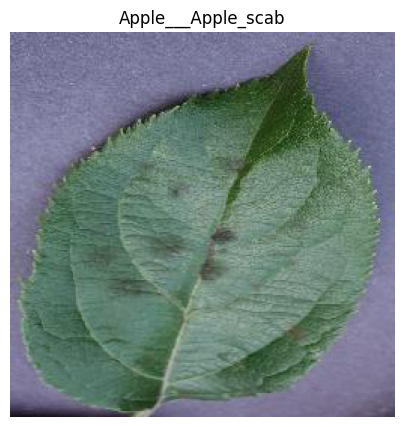

Image dimensions: (256, 256)
Class: Apple___Apple_scab


In [13]:

from PIL import Image
import matplotlib.pyplot as plt

class_name = sorted(classes)[0]
class_folder = os.path.join(color_path, class_name)

image_files = [
    f for f in os.listdir(class_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_path = os.path.join(class_folder, image_files[0])
image = Image.open(image_path)

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title(class_name)
plt.axis("off")
plt.show()

print("Image dimensions:", image.size)
print("Class:", class_name)


In [14]:

import os
import pandas as pd

class_counts = []

for class_name in sorted(classes):
    class_folder = os.path.join(color_path, class_name)

    image_files = [
        f for f in os.listdir(class_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    class_counts.append({
        "class": class_name,
        "image_count": len(image_files)
    })

counts_df = pd.DataFrame(class_counts)

print("Total classes:", len(counts_df))
print("Total images:", counts_df["image_count"].sum())

display(counts_df)


Total classes: 22
Total images: 26236


,class,image_count
0,Apple___Apple_scab,630
1,Apple___Black_rot,621
2,Apple___Cedar_apple_rust,275
3,Apple___healthy,1645
4,Blueberry___healthy,1502
5,Cherry_(including_sour)___Powdery_mildew,1052
6,Cherry_(including_sour)___healthy,854
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,513
8,Corn_(maize)___Common_rust_,1192
9,Corn_(maize)___Northern_Leaf_Blight,985


In [15]:

print("Classes with the most images:")
display(counts_df.sort_values(
    "image_count", ascending=False
).head(5))

print("Classes with the fewest images:")
display(counts_df.sort_values(
    "image_count", ascending=True
).head(5))


Classes with the most images:


,class,image_count
15,Orange___Haunglongbing_(Citrus_greening),5507
16,Peach___Bacterial_spot,2297
3,Apple___healthy,1645
4,Blueberry___healthy,1502
19,"Pepper,_bell___healthy",1478


Classes with the fewest images:


,class,image_count
21,Potato___Late_blight,104
2,Apple___Cedar_apple_rust,275
17,Peach___healthy,360
14,Grape___healthy,423
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,513


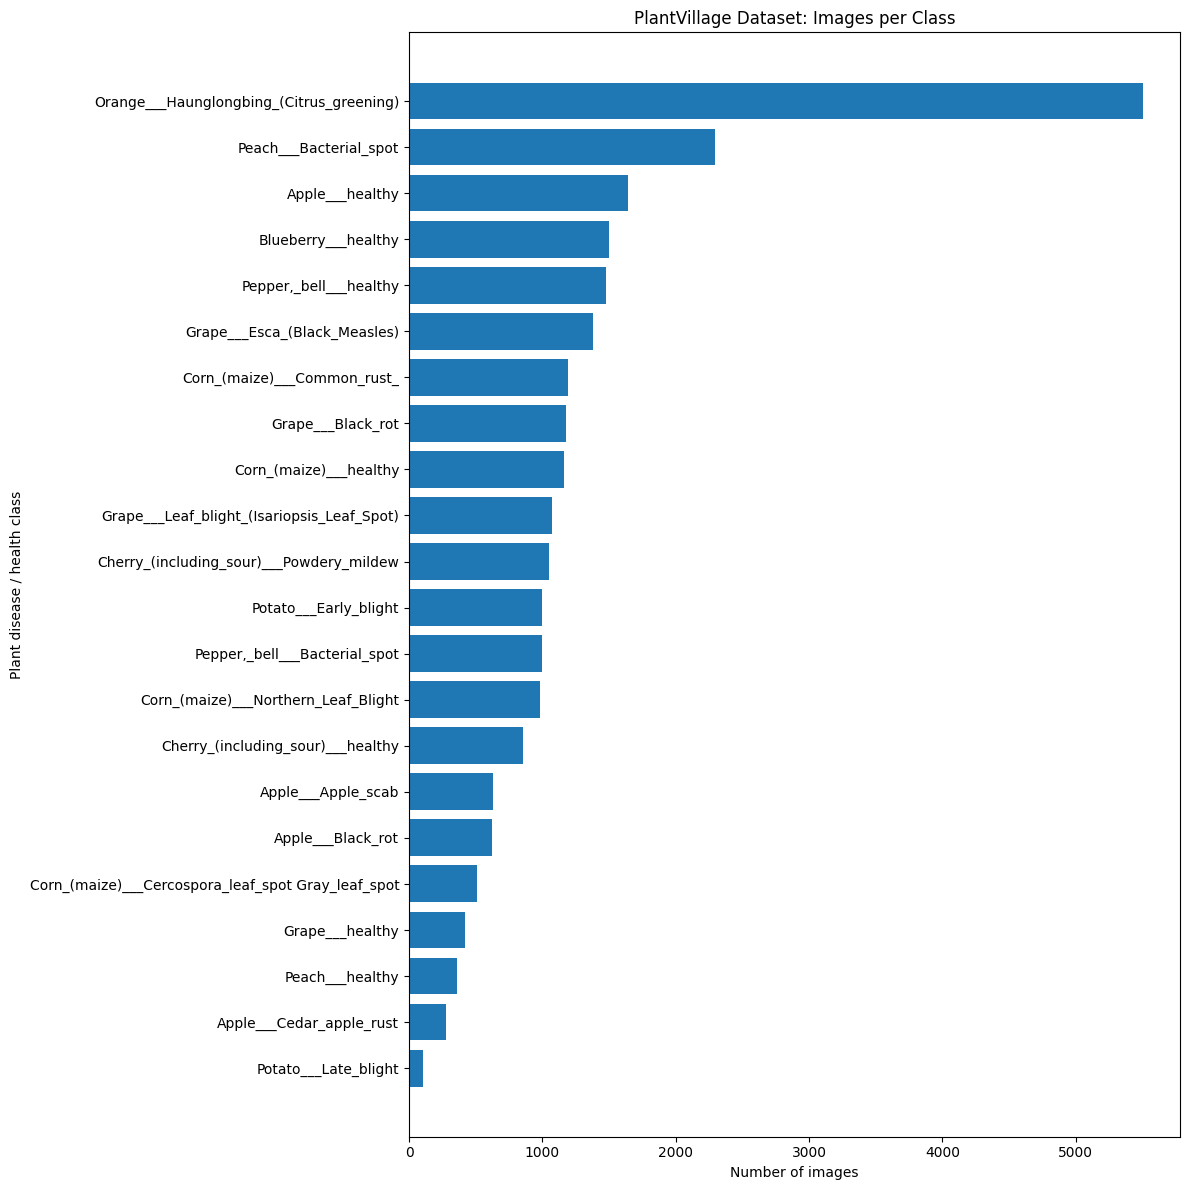

In [16]:

import matplotlib.pyplot as plt

# Sort classes from fewest to most images
plot_df = counts_df.sort_values("image_count")

plt.figure(figsize=(12, 12))
plt.barh(plot_df["class"], plot_df["image_count"])
plt.xlabel("Number of images")
plt.ylabel("Plant disease / health class")
plt.title("PlantVillage Dataset: Images per Class")
plt.tight_layout()
plt.show()


In [17]:

total_images = counts_df["image_count"].sum()
mean_images = counts_df["image_count"].mean()
median_images = counts_df["image_count"].median()
min_images = counts_df["image_count"].min()
max_images = counts_df["image_count"].max()

print(f"Total images: {total_images:,}")
print(f"Average images per class: {mean_images:.1f}")
print(f"Median images per class: {median_images:.1f}")
print(f"Fewest images in a class: {min_images:,}")
print(f"Most images in a class: {max_images:,}")
print(f"Largest-to-smallest ratio: {max_images / min_images:.1f}x")


Total images: 26,236
Average images per class: 1192.5
Median images per class: 1026.0
Fewest images in a class: 104
Most images in a class: 5,507
Largest-to-smallest ratio: 53.0x


In [18]:

for folder in ["train", "val", "validation", "test"]:
    path = os.path.join(color_path, folder)
    print(f"{folder}: {os.path.isdir(path)}")


train: False
val: False
validation: False
test: False


In [19]:

import os
import hashlib
from collections import defaultdict

hash_to_paths = defaultdict(list)

for class_name in sorted(classes):
    class_folder = os.path.join(color_path, class_name)

    for filename in os.listdir(class_folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            path = os.path.join(class_folder, filename)

            with open(path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            hash_to_paths[file_hash].append((class_name, path))

duplicate_groups = [
    paths for paths in hash_to_paths.values()
    if len(paths) > 1
]

print("Unique file-content hashes:", len(hash_to_paths))
print("Groups of exact duplicate files:", len(duplicate_groups))

cross_class_duplicates = [
    paths for paths in duplicate_groups
    if len(set(class_name for class_name, _ in paths)) > 1
]

print("Duplicate groups across different classes:",
      len(cross_class_duplicates))


Unique file-content hashes: 26229
Groups of exact duplicate files: 7
Duplicate groups across different classes: 0


In [20]:

from sklearn.model_selection import train_test_split
from collections import Counter
import os

# Build the image-path and label lists.
image_paths = []
labels = []

for class_name in sorted(classes):
    class_folder = os.path.join(color_path, class_name)

    for filename in os.listdir(class_folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(class_folder, filename))
            labels.append(class_name)

# First split: 70% training, 30% temporary.
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: divide the temporary set equally.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))
print("Total:", len(X_train) + len(X_val) + len(X_test))
print("Original total:", len(image_paths))
print("Number of classes:", len(set(labels)))


Training images: 18365
Validation images: 3935
Test images: 3936
Total: 26236
Original total: 26236
Number of classes: 22


In [21]:

train_counts = Counter(y_train)
val_counts = Counter(y_val)
test_counts = Counter(y_test)

print("Classes in training:", len(train_counts))
print("Classes in validation:", len(val_counts))
print("Classes in testing:", len(test_counts))

print("\nExample class counts:")
for class_name in sorted(classes)[:10]:
    print(
        f"{class_name}: "
        f"train={train_counts[class_name]}, "
        f"val={val_counts[class_name]}, "
        f"test={test_counts[class_name]}"
    )


Classes in training: 22
Classes in validation: 22
Classes in testing: 22

Example class counts:
Apple___Apple_scab: train=441, val=95, test=94
Apple___Black_rot: train=435, val=93, test=93
Apple___Cedar_apple_rust: train=193, val=41, test=41
Apple___healthy: train=1151, val=247, test=247
Blueberry___healthy: train=1051, val=225, test=226
Cherry_(including_sour)___Powdery_mildew: train=736, val=158, test=158
Cherry_(including_sour)___healthy: train=598, val=128, test=128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: train=359, val=77, test=77
Corn_(maize)___Common_rust_: train=834, val=179, test=179
Corn_(maize)___Northern_Leaf_Blight: train=690, val=148, test=147


In [22]:

# Map each image path to the split it belongs to.
path_to_split = {}

for path in X_train:
    path_to_split[path] = "train"

for path in X_val:
    path_to_split[path] = "validation"

for path in X_test:
    path_to_split[path] = "test"

leaking_groups = []

for paths in hash_to_paths.values():
    splits_present = {
        path_to_split[path]
        for _, path in paths
        if path in path_to_split
    }

    if len(splits_present) > 1:
        leaking_groups.append((splits_present, paths))

print("Duplicate groups crossing splits:", len(leaking_groups))

for splits_present, paths in leaking_groups[:5]:
    print("\nSplits:", sorted(splits_present))
    for class_name, path in paths:
        if path in path_to_split:
            print(path_to_split[path], "|", class_name, "|", os.path.basename(path))



Duplicate groups crossing splits: 3

Splits: ['train', 'validation']
validation | Apple___healthy | acb21cc2-8d65-4880-a7bb-dcc1eab1564b___RS_HL 6272.JPG
train | Apple___healthy | 3d075f90-7002-4c45-abc0-4f35ee49aa79___RS_HL 6272.JPG

Splits: ['test', 'train']
train | Apple___healthy | fdbfa6f7-f887-442d-8df1-1f0cf839fc4d___RS_HL 6274.JPG
test | Apple___healthy | f2cda910-55c7-46d7-b1a2-9a3bb9792148___RS_HL 6274.JPG

Splits: ['test', 'train']
train | Apple___healthy | 1ab5e019-e5f0-4d8e-a252-94cb0aab8b0a___RS_HL 6269.JPG
test | Apple___healthy | 3673d121-b5de-481c-b057-d4ee5b4959b1___RS_HL 6269.JPG


In [23]:

!pip install -q torch torchvision

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch version: 2.11.0+cu130
GPU available: True


In [24]:

from sklearn.model_selection import train_test_split
from collections import Counter
import os

# Keep one file from each exact-content group.
unique_paths = []
unique_labels = []

for file_hash, items in hash_to_paths.items():
    class_names = {class_name for class_name, path in items}

    if len(class_names) != 1:
        print("Warning: identical content has different labels:", class_names)
        continue

    class_name, path = items[0]
    unique_paths.append(path)
    unique_labels.append(class_name)

print("Images after exact deduplication:", len(unique_paths))
print("Classes:", len(set(unique_labels)))

# Split into 70% train, 15% validation, 15% test.
X_train, X_temp, y_train, y_temp = train_test_split(
    unique_paths,
    unique_labels,
    test_size=0.30,
    random_state=42,
    stratify=unique_labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nTraining:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))
print("Total:", len(X_train) + len(X_val) + len(X_test))


Images after exact deduplication: 26229
Classes: 22

Training: 18360
Validation: 3934
Testing: 3935
Total: 26229


In [25]:

path_to_split = {}

for path in X_train:
    path_to_split[path] = "train"
for path in X_val:
    path_to_split[path] = "validation"
for path in X_test:
    path_to_split[path] = "test"

leaking_groups = []

for paths in hash_to_paths.values():
    splits_present = {
        path_to_split[path]
        for _, path in paths
        if path in path_to_split
    }
    if len(splits_present) > 1:
        leaking_groups.append(paths)

print("Duplicate groups crossing splits:", len(leaking_groups))
print("Classes in train:", len(set(y_train)))
print("Classes in validation:", len(set(y_val)))
print("Classes in test:", len(set(y_test)))


Duplicate groups crossing splits: 0
Classes in train: 22
Classes in validation: 22
Classes in test: 22


In [26]:

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import torch

# Give each class a consistent numeric ID.
class_names = sorted(set(unique_labels))
class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

# Resize images and convert them to tensors.
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

class PlantLeafDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]
        label = self.labels[index]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, class_to_idx[label]

train_dataset = PlantLeafDataset(
    X_train, y_train, image_transform
)
val_dataset = PlantLeafDataset(
    X_val, y_val, image_transform
)
test_dataset = PlantLeafDataset(
    X_test, y_test, image_transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Number of classes:", len(class_names))


Training samples: 18360
Validation samples: 3934
Test samples: 3935
Number of classes: 22


In [27]:

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

images, labels_batch = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels_batch.shape)
print("First five numeric labels:", labels_batch[:5].tolist())
print("First five class names:", [
    class_names[i] for i in labels_batch[:5].tolist()
])


Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
First five numeric labels: [11, 12, 15, 15, 3]
First five class names: ['Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Orange___Haunglongbing_(Citrus_greening)', 'Orange___Haunglongbing_(Citrus_greening)', 'Apple___healthy']


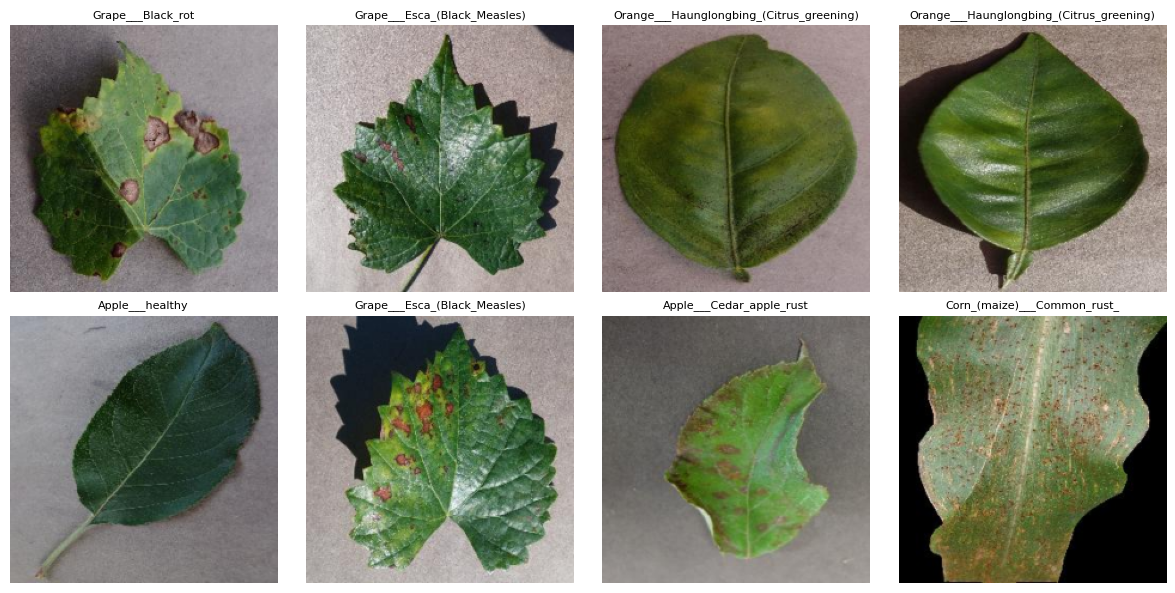

In [28]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0).numpy()
    ax.imshow(image)
    ax.set_title(class_names[labels_batch[i].item()], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [29]:

import torch
import torch.nn as nn
from torchvision import models

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Using device:", device)

# Load pretrained ResNet18 weights.
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Replace the final layer for our 38 plant classes.
model.fc = nn.Linear(model.fc.in_features, len(class_names))

model = model.to(device)

# Freeze the pretrained feature extractor for the first experiment.
for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

print("Model ready!")
print("Output classes:", model.fc.out_features)


Using device: cuda
Model ready!
Output classes: 22


In [30]:

for name in ["X_train", "y_train", "X_val", "y_val",
             "X_test", "y_test", "classes", "color_path"]:
    print(name, "exists:", name in globals())


X_train exists: True
y_train exists: True
X_val exists: True
y_val exists: True
X_test exists: True
y_test exists: True
classes exists: True
color_path exists: True


In [35]:

import os

base_path = "/content/PlantVillage-Dataset"
color_path = os.path.join(base_path, "raw", "color")

print("Dataset folder exists:", os.path.isdir(base_path))
print("Color images folder exists:", os.path.isdir(color_path))

if os.path.isdir(color_path):
    classes = sorted([
        name for name in os.listdir(color_path)
        if os.path.isdir(os.path.join(color_path, name))
    ])
    print("Number of classes:", len(classes))


Dataset folder exists: True
Color images folder exists: True
Number of classes: 22


In [36]:
import os

print("Dataset path:", color_path)
print("\nClass folders found:")

for name in classes:
    folder = os.path.join(color_path, name)
    image_count = sum(
        1 for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    )
    print(f"{name}: {image_count} images")

print("\nTotal class folders:", len(classes))

Dataset path: /content/PlantVillage-Dataset/raw/color

Class folders found:
Apple___Apple_scab: 630 images
Apple___Black_rot: 621 images
Apple___Cedar_apple_rust: 275 images
Apple___healthy: 1645 images
Blueberry___healthy: 1502 images
Cherry_(including_sour)___Powdery_mildew: 1052 images
Cherry_(including_sour)___healthy: 854 images
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513 images
Corn_(maize)___Common_rust_: 1192 images
Corn_(maize)___Northern_Leaf_Blight: 985 images
Corn_(maize)___healthy: 1162 images
Grape___Black_rot: 1180 images
Grape___Esca_(Black_Measles): 1383 images
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076 images
Grape___healthy: 423 images
Orange___Haunglongbing_(Citrus_greening): 5507 images
Peach___Bacterial_spot: 2297 images
Peach___healthy: 360 images
Pepper,_bell___Bacterial_spot: 997 images
Pepper,_bell___healthy: 1478 images
Potato___Early_blight: 1000 images
Potato___Late_blight: 104 images

Total class folders: 22


In [37]:
for root, dirs, files in os.walk(base_path):
    image_count = sum(
        1 for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    )
    if image_count > 0:
        print(f"{root}: {image_count} images")

/content/PlantVillage-Dataset/raw/color/Potato___Late_blight: 104 images
/content/PlantVillage-Dataset/raw/color/Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513 images
/content/PlantVillage-Dataset/raw/color/Grape___healthy: 423 images
/content/PlantVillage-Dataset/raw/color/Apple___Apple_scab: 630 images
/content/PlantVillage-Dataset/raw/color/Apple___Cedar_apple_rust: 275 images
/content/PlantVillage-Dataset/raw/color/Grape___Black_rot: 1180 images
/content/PlantVillage-Dataset/raw/color/Corn_(maize)___Common_rust_: 1192 images
/content/PlantVillage-Dataset/raw/color/Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076 images
/content/PlantVillage-Dataset/raw/color/Pepper,_bell___healthy: 1478 images
/content/PlantVillage-Dataset/raw/color/Orange___Haunglongbing_(Citrus_greening): 5507 images
/content/PlantVillage-Dataset/raw/color/Corn_(maize)___Northern_Leaf_Blight: 985 images
/content/PlantVillage-Dataset/raw/color/Cherry_(including_sour)___Powdery_mildew: 1052 images
/content

In [38]:
import os

svm_path = os.path.join(base_path, "data_distribution_for_SVM")

print("SVM folder exists:", os.path.isdir(svm_path))

if os.path.isdir(svm_path):
    for split in ["train", "test"]:
        split_path = os.path.join(svm_path, split)

        if os.path.isdir(split_path):
            class_folders = [
                name for name in os.listdir(split_path)
                if os.path.isdir(os.path.join(split_path, name))
            ]

            print(f"{split}: {len(class_folders)} numbered folders")

SVM folder exists: True
train: 38 numbered folders
test: 38 numbered folders


In [39]:
!cd /content/PlantVillage-Dataset && git status --short
!cd /content/PlantVillage-Dataset && git remote -v

Streaming output truncated to the last 5000 lines.
D  "raw/segmented/Tomato___Tomato_Yellow_Leaf_Curl_Virus/6ff8f2bf-6ba0-417b-8f85-736d191eca9b___YLCV_GCREC 2835_final_masked.jpg"
D  "raw/segmented/Tomato___Tomato_Yellow_Leaf_Curl_Virus/70009c19-7424-4ce8-96e8-9eef439e4c9e___UF.GRC_YLCV_Lab 02056_final_masked.jpg"
D  "raw/segmented/Tomato___Tomato_Yellow_Leaf_Curl_Virus/700b2b34-d31d-436f-9a7c-59491dbe908e___UF.GRC_YLCV_Lab 03314_final_masked.jpg"
D  "raw/segmented/Tomato___Tomato_Yellow_Leaf_Curl_Virus/701cc36d-bfea-4a31-81cf-df1d4784d446___UF.GRC_YLCV_Lab 02821_final_masked.jpg"
D  "raw/segmented/Tomato___Tomato_Yellow_Leaf_Curl_Virus/7030d706-3ef0-404b-84f2-d1d76ce823dd___UF.GRC_YLCV_Lab 03242_final_masked.jpg"
D  "raw/segmented/Tomato___Tomato_Yellow_Leaf_Curl_Virus/70405b14-c0d9-4060-bc08-cd424e4f28fb___UF.GRC_YLCV_Lab 01780_final_masked.jpg"
D  "raw/segmented/Tomato___Tomato_Yellow_Leaf_Curl_Virus/7063b4ca-978d-420f-9dd2-85827f7b7a43___YLCV_NREC 2505_final_masked.jpg"
D  "raw/se

In [40]:
import os
import json

mapping_path = os.path.join(base_path, "leaf-map.json")

print("Mapping file exists:", os.path.isfile(mapping_path))

if os.path.isfile(mapping_path):
    with open(mapping_path, "r") as f:
        leaf_map = json.load(f)

    print("Mapping type:", type(leaf_map).__name__)
    print("Mapping preview:")
    print(json.dumps(leaf_map, indent=2)[:4000])

Mapping file exists: True
Mapping type: dict
Mapping preview:
{
  "rutg._hl 3733": [
    "Peach___healthy:::54.0"
  ],
  "com.g_fl 8310": [
    "Tomato___Target_Spot:::243.0"
  ],
  "rs_early.b 7557": [
    "Potato___Early_blight:::115.0"
  ],
  "rs_early.b 7554": [
    "Potato___Early_blight:::115.0"
  ],
  "uf.citrus_hlb_lab 1658": [
    "Orange___Haunglongbing_(Citrus_greening):::104.0"
  ],
  "uf.citrus_hlb_lab 1659": [
    "Orange___Haunglongbing_(Citrus_greening):::104.0"
  ],
  "uf.citrus_hlb_lab 1654": [
    "Orange___Haunglongbing_(Citrus_greening):::104.0"
  ],
  "uf.citrus_hlb_lab 1655": [
    "Orange___Haunglongbing_(Citrus_greening):::104.0"
  ],
  "uf.citrus_hlb_lab 1656": [
    "Orange___Haunglongbing_(Citrus_greening):::104.0"
  ],
  "uf.citrus_hlb_lab 1657": [
    "Orange___Haunglongbing_(Citrus_greening):::104.0"
  ],
  "uf.citrus_hlb_lab 1650": [
    "Orange___Haunglongbing_(Citrus_greening):::104.0"
  ],
  "uf.citrus_hlb_lab 1651": [
    "Orange___Haunglongbing_(Cit

In [41]:
import os

for split in ["train", "test"]:
    folder = os.path.join(base_path, "data_distribution_for_SVM", split)

    print(f"\n{split.upper()}")

    for class_id in sorted(os.listdir(folder))[:5]:
        class_folder = os.path.join(folder, class_id)

        if os.path.isdir(class_folder):
            files = os.listdir(class_folder)
            print(class_id, "->", len(files), "files")
            print("  Example:", files[:2])


TRAIN
0 -> 111 files
  Example: ['2b170fa4-e929-4562-b3eb-9ca42bf7b1dd.JPG', '4afada2b-336d-4af3-956a-a97eb29f2724.JPG']
1 -> 114 files
  Example: ['196766eb-4f13-4069-8d40-b7d261b1f83d.JPG', 'a9ac4654-9c6f-4f35-ab80-22b307e5e476.JPG']
10 -> 212 files
  Example: ['42d42835-9179-4b7a-99ad-a47497a8c6f5.JPG', 'c864f5a0-2479-4c12-84b4-3998ef22d549.JPG']
11 -> 187 files
  Example: ['e313c785-e8a2-4e5c-85b4-6304ec61a9e0.JPG', '3f8e0887-dcb9-4f96-a8be-92f5962f3464.JPG']
12 -> 233 files
  Example: ['a0994034-570a-4378-9a72-a67822869ba8.JPG', '33271860-751d-4f33-acf3-3a3b20c4b851.JPG']

TEST
0 -> 110 files
  Example: ['b05a138f-85ae-4e1b-a69f-57c37fd0b436.JPG', '4ec17278-d866-45f7-bcf4-3b60280a03ba.JPG']
1 -> 85 files
  Example: ['e4a4307a-f216-4249-9ca4-7aff5c7effd0.JPG', '469a20ba-efa8-4c23-a29f-f53eb010d8e1.JPG']
10 -> 221 files
  Example: ['ae5bc9c6-9d7a-4104-8380-cef524b71c12.JPG', '4682c55b-6348-4c21-ae14-ce8bc63ddfc3.JPG']
11 -> 220 files
  Example: ['27efe8e3-4d72-4fbf-bf7a-c0bcd7325d6

In [42]:
import json
import os
from collections import Counter

mapping_path = os.path.join(base_path, "leaf-map.json")

with open(mapping_path, "r") as f:
    leaf_map = json.load(f)

# Extract the disease class from each mapping entry
labels = []

for values in leaf_map.values():
    for item in values:
        label = item.split(":::")[0]
        labels.append(label)

class_counts = Counter(labels)

print("Total mapping entries:", len(leaf_map))
print("Unique disease classes:", len(class_counts))
print("\nDisease classes found:")

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

Total mapping entries: 40328
Unique disease classes: 31

Disease classes found:
Apple_Frogeye Spot: 621
Apple___Apple_scab: 630
Apple___Cedar_apple_rust: 276
Apple___healthy: 1639
Blueberry___healthy: 1503
Cherry_(including_sour)___Powdery_mildew: 1052
Cherry_(including_sour)___healthy: 854
Grape___Black_rot: 1180
Grape___Esca_(Black_Measles): 1384
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076
Orange___Haunglongbing_(Citrus_greening): 5508
Peach___Bacterial_spot: 2297
Peach___healthy: 361
Pepper,_bell___Bacterial_spot: 997
Pepper,_bell___healthy: 1476
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152
Raspberry___healthy: 371
Soybean___healthy: 5091
Strawberry___Leaf_scorch: 776
Strawberry___healthy: 456
Tomato___Bacterial_spot: 2128
Tomato___Early_blight: 1000
Tomato___Late_blight: 920
Tomato___Leaf_Mold: 952
Tomato___Septoria_leaf_spot: 1000
Tomato___Spider_mites Two-spotted_spider_mite: 1676
Tomato___Target_Spot: 1404
Tomato___Tomato_Yellow_Leaf_Curl_Vir

In [43]:
import os

svm_path = os.path.join(base_path, "data_distribution_for_SVM")

for split in ["train", "test"]:
    split_path = os.path.join(svm_path, split)

    folders = [
        f for f in os.listdir(split_path)
        if os.path.isdir(os.path.join(split_path, f))
    ]

    total_images = 0

    print(f"\n{split.upper()}: {len(folders)} folders")

    for folder in sorted(folders, key=lambda x: int(x)):
        folder_path = os.path.join(split_path, folder)
        count = sum(
            1 for f in os.listdir(folder_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        )
        total_images += count
        print(f"Folder {folder}: {count} images")

    print("Total images:", total_images)


TRAIN: 38 folders
Folder 0: 111 images
Folder 1: 114 images
Folder 2: 39 images
Folder 3: 288 images
Folder 4: 239 images
Folder 5: 181 images
Folder 6: 132 images
Folder 7: 83 images
Folder 8: 199 images
Folder 9: 132 images
Folder 10: 212 images
Folder 11: 187 images
Folder 12: 233 images
Folder 13: 159 images
Folder 14: 67 images
Folder 15: 847 images
Folder 16: 386 images
Folder 17: 74 images
Folder 18: 158 images
Folder 19: 241 images
Folder 20: 153 images
Folder 21: 168 images
Folder 22: 25 images
Folder 23: 44 images
Folder 24: 885 images
Folder 25: 270 images
Folder 26: 187 images
Folder 27: 84 images
Folder 28: 297 images
Folder 29: 147 images
Folder 30: 291 images
Folder 31: 146 images
Folder 32: 275 images
Folder 33: 300 images
Folder 34: 211 images
Folder 35: 897 images
Folder 36: 65 images
Folder 37: 224 images
Total images: 8751

TEST: 38 folders
Folder 0: 110 images
Folder 1: 85 images
Folder 2: 60 images
Folder 3: 266 images
Folder 4: 229 images
Folder 5: 228 images
Fo

In [44]:
import os
import json

svm_path = os.path.join(base_path, "data_distribution_for_SVM")

with open(os.path.join(base_path, "leaf-map.json"), "r") as f:
    leaf_map = json.load(f)

# Pick one image from numbered training folder 0
folder_path = os.path.join(svm_path, "train", "0")
example_file = next(
    f for f in os.listdir(folder_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
)

print("Example image filename:", example_file)
print("Filename without extension:", os.path.splitext(example_file)[0])

print("\nDoes the filename match a mapping key?")
print(example_file in leaf_map)
print(os.path.splitext(example_file)[0] in leaf_map)

print("\nMapping entry for the example, if found:")
print(leaf_map.get(example_file, leaf_map.get(os.path.splitext(example_file)[0], "No direct match")))

Example image filename: 2b170fa4-e929-4562-b3eb-9ca42bf7b1dd.JPG
Filename without extension: 2b170fa4-e929-4562-b3eb-9ca42bf7b1dd

Does the filename match a mapping key?
False
False

Mapping entry for the example, if found:
No direct match


In [45]:
import os

base_path = "/content/PlantVillage-Dataset"

print("Dataset root folders:")
for name in sorted(os.listdir(base_path)):
    full_path = os.path.join(base_path, name)
    if os.path.isdir(full_path):
        print(name)

print("\nSVM folder 0 — sample filenames:")
folder = os.path.join(
    base_path, "data_distribution_for_SVM", "train", "0"
)
print(os.listdir(folder)[:10])

print("\nRaw/color class folders:")
color_path = os.path.join(base_path, "raw", "color")
if os.path.isdir(color_path):
    print("Number of folders:", len([
        name for name in os.listdir(color_path)
        if os.path.isdir(os.path.join(color_path, name))
    ]))
    print(sorted(os.listdir(color_path)))

Dataset root folders:
.git
data_distribution_for_SVM
generated_for_paper
leaf_grouping
logs
raw

SVM folder 0 — sample filenames:
['2b170fa4-e929-4562-b3eb-9ca42bf7b1dd.JPG', '4afada2b-336d-4af3-956a-a97eb29f2724.JPG', '21f28ae9-c700-486d-b9bd-9436ef2787e1.JPG', 'fe9a2f8c-50b9-4307-95e5-bf8168a23516.JPG', '4d41a9f6-915a-4164-a87d-d4826bc1eeed.JPG', '00b9027b-5503-4be0-b8cc-ae6796c422b6.JPG', '581e3d3b-c65a-4b0e-a693-3c722edf8169.JPG', '47be189e-bcc2-4144-91f0-51fef9b1f4af.JPG', 'bcf0e0e5-3024-4698-bbbc-df9b5dfd52ce.JPG', '8eee7f08-75d7-40c2-bb4b-818bf35e207c.JPG']

Raw/color class folders:
Number of folders: 22
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(

In [46]:
import subprocess

repo = "/content/PlantVillage-Dataset"

for title, command in [
    ("CURRENT GIT STATUS", ["git", "-C", repo, "status", "--short"]),
    ("RECENT COMMITS", ["git", "-C", repo, "log", "-5", "--oneline"]),
    ("TRACKED COLOR FOLDERS", [
        "git", "-C", repo, "ls-tree", "-d", "--name-only", "HEAD", "raw/color"
    ]),
]:
    print(f"\n--- {title} ---")
    result = subprocess.run(
        command, capture_output=True, text=True
    )
    print(result.stdout[:6000] or "(No output)")
    if result.stderr:
        print(result.stderr[:1000])


--- CURRENT GIT STATUS ---
D  .gitignore
D  CITATION.cff
D  README.md
D  README_HF.md
D  data_distribution_for_SVM/test/0/013100cc-af7f-47eb-aaef-d46215549bc6.JPG
D  data_distribution_for_SVM/test/0/025bed10-5058-4355-a2a7-b7951b9e3430.JPG
D  data_distribution_for_SVM/test/0/03ff6f74-0fb6-41f2-8fb9-dedd2612eb92.JPG
D  data_distribution_for_SVM/test/0/05bf461d-b333-4a47-a57f-10e7f1e5cee2.JPG
D  data_distribution_for_SVM/test/0/091b0712-be85-46f4-8c36-65bff8e2d8b0.JPG
D  data_distribution_for_SVM/test/0/0f1197f8-a106-4ebc-ad08-42967be969a8.JPG
D  data_distribution_for_SVM/test/0/0fe6444d-d776-43cb-a5c7-919501763818.JPG
D  data_distribution_for_SVM/test/0/1077a302-ade9-40de-be8a-bc2a72a73c37.JPG
D  data_distribution_for_SVM/test/0/1166a4e2-744d-4f4d-85fb-af90dc849a8c.JPG
D  data_distribution_for_SVM/test/0/118901bc-4caf-4219-a993-d4ba06f3e210.JPG
D  data_distribution_for_SVM/test/0/14a89055-c455-4438-a03b-b179f0f1b058.JPG
D  data_distribution_for_SVM/test/0/1aef6002-435e-42c1-ac33-47b5a0

In [47]:
import subprocess

repo = "/content/PlantVillage-Dataset"

commands = {
    "STAGED DELETIONS (first 20)": [
        "git", "-C", repo, "diff", "--cached",
        "--name-status"
    ],
    "UNSTAGED DELETIONS (first 20)": [
        "git", "-C", repo, "diff",
        "--name-status"
    ],
    "CURRENT DATASET COUNTS": [
        "bash", "-lc",
        f"find '{repo}/raw/color' -type f | wc -l"
    ],
}

for title, command in commands.items():
    print(f"\n--- {title} ---")
    result = subprocess.run(
        command, capture_output=True, text=True
    )
    if title != "CURRENT DATASET COUNTS":
        lines = result.stdout.splitlines()
        print("\n".join(lines[:20]) or "(No changes reported)")
        print(f"Total reported changes: {len(lines)}")
    else:
        print(result.stdout.strip())
    if result.stderr:
        print(result.stderr[:500])


--- STAGED DELETIONS (first 20) ---
D	.gitignore
D	CITATION.cff
D	README.md
D	README_HF.md
D	data_distribution_for_SVM/test/0/013100cc-af7f-47eb-aaef-d46215549bc6.JPG
D	data_distribution_for_SVM/test/0/025bed10-5058-4355-a2a7-b7951b9e3430.JPG
D	data_distribution_for_SVM/test/0/03ff6f74-0fb6-41f2-8fb9-dedd2612eb92.JPG
D	data_distribution_for_SVM/test/0/05bf461d-b333-4a47-a57f-10e7f1e5cee2.JPG
D	data_distribution_for_SVM/test/0/091b0712-be85-46f4-8c36-65bff8e2d8b0.JPG
D	data_distribution_for_SVM/test/0/0f1197f8-a106-4ebc-ad08-42967be969a8.JPG
D	data_distribution_for_SVM/test/0/0fe6444d-d776-43cb-a5c7-919501763818.JPG
D	data_distribution_for_SVM/test/0/1077a302-ade9-40de-be8a-bc2a72a73c37.JPG
D	data_distribution_for_SVM/test/0/1166a4e2-744d-4f4d-85fb-af90dc849a8c.JPG
D	data_distribution_for_SVM/test/0/118901bc-4caf-4219-a993-d4ba06f3e210.JPG
D	data_distribution_for_SVM/test/0/14a89055-c455-4438-a03b-b179f0f1b058.JPG
D	data_distribution_for_SVM/test/0/1aef6002-435e-42c1-ac33-47b5a07e88b3.

In [48]:
import subprocess
from pathlib import Path
from collections import Counter

repo = Path("/content/PlantVillage-Dataset")

def git(*args):
    result = subprocess.run(
        ["git", "-C", str(repo), *args],
        capture_output=True, text=True
    )
    return result.stdout.splitlines()

# Files staged for deletion
deleted = [
    line.split("\t", 1)[1]
    for line in git("diff", "--cached", "--name-status")
    if line.startswith("D\t")
]

print("Staged deletions:", len(deleted))

# Which parts of the repository are affected?
counts = Counter(path.split("/", 1)[0] for path in deleted)
print("\nStaged deletions by top-level folder:")
for folder, count in counts.most_common(15):
    print(f"{folder}: {count}")

# Check whether a few deleted files still exist on disk
print("\nSample file checks:")
for relative_path in deleted[:10]:
    exists = (repo / relative_path).exists()
    print(f"{'EXISTS' if exists else 'MISSING'}: {relative_path}")

# Check whether key repository files exist
print("\nImportant files:")
for name in [".gitignore", "README.md", "CITATION.cff", "leaf-map.json"]:
    print(f"{name}: {'EXISTS' if (repo / name).exists() else 'MISSING'}")

Staged deletions: 182404

Staged deletions by top-level folder:
raw: 162916
data_distribution_for_SVM: 19300
leaf_grouping: 80
generated_for_paper: 62
scripts: 18
logs: 15
utils: 4
.gitignore: 1
CITATION.cff: 1
README.md: 1
README_HF.md: 1
generate_data_for_SVM.py: 1
generate_lmdb.sh: 1
generate_mapstring.py: 1
leaf-map.json: 1

Sample file checks:
EXISTS: .gitignore
EXISTS: CITATION.cff
EXISTS: README.md
EXISTS: README_HF.md
EXISTS: data_distribution_for_SVM/test/0/013100cc-af7f-47eb-aaef-d46215549bc6.JPG
EXISTS: data_distribution_for_SVM/test/0/025bed10-5058-4355-a2a7-b7951b9e3430.JPG
EXISTS: data_distribution_for_SVM/test/0/03ff6f74-0fb6-41f2-8fb9-dedd2612eb92.JPG
EXISTS: data_distribution_for_SVM/test/0/05bf461d-b333-4a47-a57f-10e7f1e5cee2.JPG
EXISTS: data_distribution_for_SVM/test/0/091b0712-be85-46f4-8c36-65bff8e2d8b0.JPG
EXISTS: data_distribution_for_SVM/test/0/0f1197f8-a106-4ebc-ad08-42967be969a8.JPG

Important files:
.gitignore: EXISTS
README.md: EXISTS
CITATION.cff: EXISTS
le

In [49]:
import subprocess
from pathlib import Path

repo = Path("/content/PlantVillage-Dataset")

result = subprocess.run(
    ["git", "-C", str(repo), "diff", "--cached",
     "--name-only", "--diff-filter=D"],
    capture_output=True, text=True, check=True
)

paths = result.stdout.splitlines()
existing = sum((repo / p).exists() for p in paths)
missing = len(paths) - existing

print("Staged deleted paths:", len(paths))
print("Paths that still exist:", existing)
print("Paths actually missing:", missing)

Staged deleted paths: 182404
Paths that still exist: 45702
Paths actually missing: 136702


In [50]:
import subprocess
from pathlib import Path
from collections import Counter

repo = Path("/content/PlantVillage-Dataset")

result = subprocess.run(
    ["git", "-C", str(repo), "diff", "--cached",
     "--name-only", "--diff-filter=D"],
    capture_output=True, text=True, check=True
)

paths = result.stdout.splitlines()
missing = [p for p in paths if not (repo / p).exists()]
existing = [p for p in paths if (repo / p).exists()]

def folder_group(path):
    parts = Path(path).parts
    return parts[0] if parts else "(root)"

print("MISSING FILES BY TOP-LEVEL FOLDER:")
for folder, count in Counter(map(folder_group, missing)).most_common():
    print(f"{folder}: {count}")

print("\nFILES THAT STILL EXIST BY TOP-LEVEL FOLDER:")
for folder, count in Counter(map(folder_group, existing)).most_common():
    print(f"{folder}: {count}")

print("\nEXAMPLES OF MISSING PATHS:")
for path in missing[:15]:
    print(path)

print("\nOTHER STAGED CHANGE TYPES:")
result = subprocess.run(
    ["git", "-C", str(repo), "diff", "--cached",
     "--name-status", "--diff-filter=ACMRT"],
    capture_output=True, text=True, check=True
)
print(result.stdout[:3000] or "No staged additions, modifications, renames, or copies.")

MISSING FILES BY TOP-LEVEL FOLDER:
raw: 136680
scripts: 18
utils: 4

FILES THAT STILL EXIST BY TOP-LEVEL FOLDER:
raw: 26236
data_distribution_for_SVM: 19300
leaf_grouping: 80
generated_for_paper: 62
logs: 15
.gitignore: 1
CITATION.cff: 1
README.md: 1
README_HF.md: 1
generate_data_for_SVM.py: 1
generate_lmdb.sh: 1
generate_mapstring.py: 1
leaf-map.json: 1
plant_village.py: 1

EXAMPLES OF MISSING PATHS:
raw/color/Potato___Late_blight/1cd053f6-0016-4680-a924-af15aecd7fb2___RS_LB 4414.JPG
raw/color/Potato___Late_blight/1cd0b065-e637-4307-9e0a-9c20dc44cc59___RS_LB 4784.JPG
raw/color/Potato___Late_blight/1cffe6a1-6fb3-4506-846c-478148a2b678___RS_LB 4380.JPG
raw/color/Potato___Late_blight/1d05837e-11e4-40a4-8bd5-cfe5ad67365a___RS_LB 5428.JPG
raw/color/Potato___Late_blight/1d389389-0585-433a-83c7-30b42db2ca3f___RS_LB 3322.JPG
raw/color/Potato___Late_blight/1d4acd15-f2b9-4a2e-87da-9d5a2cc6a642___RS_LB 2752.JPG
raw/color/Potato___Late_blight/1dc41475-aa79-43f1-8648-0c8733d246ca___RS_LB 3319.JPG


In [51]:
import subprocess
from pathlib import Path

repo = Path("/content/PlantVillage-Dataset")

commands = {
    "current_commit": ["git", "-C", str(repo), "rev-parse", "--short", "HEAD"],
    "staged_deletions": ["git", "-C", str(repo), "diff", "--cached", "--stat"],
    "working_tree": ["git", "-C", str(repo), "status", "--short"],
}

for name, command in commands.items():
    result = subprocess.run(command, capture_output=True, text=True)
    print(f"\n--- {name} ---")
    print(result.stdout[:5000] or "(no output)")
    if result.stderr:
        print("Message:", result.stderr[:1000])

# Check whether a representative missing image exists in the current Git commit.
sample = "raw/color/Potato___Late_blight/1cd053f6-0016-4680-a924-af15aecd7fb2___RS_LB 4414.JPG"
result = subprocess.run(
    ["git", "-C", str(repo), "cat-file", "-e", f"HEAD:{sample}"],
    capture_output=True, text=True
)
print("\nSample image stored in current commit:", result.returncode == 0)


--- current_commit ---
7f7ecc7e1


--- staged_deletions ---
 .gitignore                                         |   219 -
 CITATION.cff                                       |    27 -
 README.md                                          |   102 -
 README_HF.md                                       |   180 -
 .../0/013100cc-af7f-47eb-aaef-d46215549bc6.JPG     |   Bin 9406 -> 0 bytes
 .../0/025bed10-5058-4355-a2a7-b7951b9e3430.JPG     |   Bin 12365 -> 0 bytes
 .../0/03ff6f74-0fb6-41f2-8fb9-dedd2612eb92.JPG     |   Bin 9400 -> 0 bytes
 .../0/05bf461d-b333-4a47-a57f-10e7f1e5cee2.JPG     |   Bin 10987 -> 0 bytes
 .../0/091b0712-be85-46f4-8c36-65bff8e2d8b0.JPG     |   Bin 14867 -> 0 bytes
 .../0/0f1197f8-a106-4ebc-ad08-42967be969a8.JPG     |   Bin 18849 -> 0 bytes
 .../0/0fe6444d-d776-43cb-a5c7-919501763818.JPG     |   Bin 12133 -> 0 bytes
 .../0/1077a302-ade9-40de-be8a-bc2a72a73c37.JPG     |   Bin 12068 -> 0 bytes
 .../0/1166a4e2-744d-4f4d-85fb-af90dc849a8c.JPG     |   Bin 15734 -> 0 bytes


In [52]:
import subprocess
from pathlib import Path

repo = Path("/content/PlantVillage-Dataset")

checks = [
    ("Missing original image",
     "raw/color/Potato___Late_blight/1cd053f6-0016-4680-a924-af15aecd7fb2___RS_LB 4414.JPG"),
    ("Existing SVM image",
     "data_distribution_for_SVM/test/0/013100cc-af7f-47eb-aaef-d46215549bc6.JPG"),
]

for label, path in checks:
    in_commit = subprocess.run(
        ["git", "-C", str(repo), "cat-file", "-e", f"HEAD:{path}"],
        capture_output=True
    ).returncode == 0

    on_disk = (repo / path).exists()

    print(f"{label}:")
    print(f"  In current Git commit: {in_commit}")
    print(f"  Exists on disk:        {on_disk}")

Missing original image:
  In current Git commit: True
  Exists on disk:        False
Existing SVM image:
  In current Git commit: True
  Exists on disk:        True


In [53]:
import subprocess

repo = "/content/PlantVillage-Dataset"

result = subprocess.run(
    ["git", "-C", repo, "restore",
     "--source=HEAD", "--staged", "--worktree", "--", "."],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout or "(no output)")
print(result.stderr or "(no errors)")

Return code: 0
(no output)
(no errors)


In [54]:
from pathlib import Path
import subprocess

repo = Path("/content/PlantVillage-Dataset")

sample = repo / (
    "raw/color/Potato___Late_blight/"
    "1cd053f6-0016-4680-a924-af15aecd7fb2___RS_LB 4414.JPG"
)

print("Sample original recovered:", sample.exists())

result = subprocess.run(
    ["git", "-C", str(repo), "status", "--short"],
    capture_output=True, text=True, check=True
)

print("Git status:")
print(result.stdout or "Clean working tree")

Sample original recovered: True
Git status:
Clean working tree


In [55]:
from pathlib import Path

repo = Path("/content/PlantVillage-Dataset")
color_dir = repo / "raw" / "color"

print("Color dataset exists:", color_dir.exists())

if color_dir.exists():
    class_folders = sorted(
        p for p in color_dir.iterdir()
        if p.is_dir()
    )

    total_images = 0

    print("Number of classes:", len(class_folders))
    print("\nImages per class:")

    for folder in class_folders:
        count = sum(
            1 for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".bmp", ".webp"
            }
        )
        total_images += count
        print(f"{folder.name}: {count}")

    print("\nTotal images:", total_images)

Color dataset exists: True
Number of classes: 38

Images per class:
Apple___Apple_scab: 630
Apple___Black_rot: 621
Apple___Cedar_apple_rust: 275
Apple___healthy: 1645
Blueberry___healthy: 1502
Cherry_(including_sour)___Powdery_mildew: 1052
Cherry_(including_sour)___healthy: 854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513
Corn_(maize)___Common_rust_: 1192
Corn_(maize)___Northern_Leaf_Blight: 985
Corn_(maize)___healthy: 1162
Grape___Black_rot: 1180
Grape___Esca_(Black_Measles): 1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076
Grape___healthy: 423
Orange___Haunglongbing_(Citrus_greening): 5507
Peach___Bacterial_spot: 2297
Peach___healthy: 360
Pepper,_bell___Bacterial_spot: 997
Pepper,_bell___healthy: 1478
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152
Raspberry___healthy: 371
Soybean___healthy: 5090
Squash___Powdery_mildew: 1835
Strawberry___Leaf_scorch: 1109
Strawberry___healthy: 456
Tomato___Bacterial_spot: 2127
Tomato___Early_blight: 1000


In [56]:
from pathlib import Path

repo = Path("/content/PlantVillage-Dataset")

for folder_name in ["leaf_grouping", "raw"]:
    folder = repo / folder_name
    print(f"\n{folder_name}/")

    if folder.exists():
        for path in sorted(folder.iterdir()):
            kind = "folder" if path.is_dir() else "file"
            print(f"  {kind}: {path.name}")
    else:
        print("  Folder not found")

print("\nPossible leaf-mapping files:")

for path in repo.rglob("*"):
    if path.is_file() and (
        "leafmap" in path.name.lower()
        or "leaf_map" in path.name.lower()
    ):
        print(path.relative_to(repo))


leaf_grouping/
  file: Google Leaf Counts.zip
  file: aggregate_map.py
  file: create_map.py
  folder: filtered_leafmaps
  file: leaf-map.json
  folder: leaf_maps

raw/
  folder: color
  folder: grayscale
  folder: segmented

Possible leaf-mapping files:


In [57]:
import json
from pathlib import Path

repo = Path("/content/PlantVillage-Dataset")
mapping_file = repo / "leaf_grouping" / "leaf-map.json"

print("Mapping file exists:", mapping_file.exists())

if mapping_file.exists():
    with open(mapping_file, "r") as f:
        leaf_map = json.load(f)

    print("Mapping entries:", len(leaf_map))
    print("\nFirst 5 entries:")

    for i, (key, value) in enumerate(leaf_map.items()):
        print(key, "->", value)
        if i == 4:
            break

print("\nOther mapping files:")
for folder_name in ["leaf_maps", "filtered_leafmaps"]:
    folder = repo / "leaf_grouping" / folder_name
    print(f"\n{folder_name}:")

    if folder.exists():
        for path in sorted(folder.iterdir())[:10]:
            print(" ", path.name)

Mapping file exists: True
Mapping entries: 40328

First 5 entries:
rutg._hl 3733 -> ['Peach___healthy:::54.0']
com.g_fl 8310 -> ['Tomato___Target_Spot:::243.0']
rs_early.b 7557 -> ['Potato___Early_blight:::115.0']
rs_early.b 7554 -> ['Potato___Early_blight:::115.0']
uf.citrus_hlb_lab 1658 -> ['Orange___Haunglongbing_(Citrus_greening):::104.0']

Other mapping files:

leaf_maps:
  Apple Leaf Counts.xlsx
  Apple_Cedar Apple Rust.csv
  Apple_Frogeye Spot.csv
  Apple_Healthy.csv
  Apple_Scab.csv
  Blueberry Leaf Counts.xlsx
  Blueberry_Healthy.csv
  Cherry Leaf Counts.xlsx
  Cherry_Healthy.csv
  Cherry_Powdery Mildew.csv

filtered_leafmaps:
  Apple_Frogeye Spot.csv
  Apple___Apple_scab.csv
  Apple___Cedar_apple_rust.csv
  Apple___healthy.csv
  Blueberry___healthy.csv
  Cherry_(including_sour)___Powdery_mildew.csv
  Cherry_(including_sour)___healthy.csv
  Grape___Black_rot.csv
  Grape___Esca_(Black_Measles).csv
  Grape___Leaf_blight_(Isariopsis_Leaf_Spot).csv


In [58]:
import json
from pathlib import Path

repo = Path("/content/PlantVillage-Dataset")
color_dir = repo / "raw" / "color"
mapping_file = repo / "leaf_grouping" / "leaf-map.json"

with open(mapping_file, "r") as f:
    leaf_map = json.load(f)

# Collect image filenames and stems
image_paths = [
    p for p in color_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }
]

filenames = {p.name for p in image_paths}
stems = {p.stem for p in image_paths}

# Test whether mapping keys directly match filenames or stems
keys = list(leaf_map.keys())
filename_matches = sum(key in filenames for key in keys)
stem_matches = sum(key in stems for key in keys)

print("Images found:", len(image_paths))
print("Mapping entries:", len(keys))
print("Keys matching filenames:", filename_matches)
print("Keys matching filename stems:", stem_matches)

print("\nExample mapping keys:")
for key in keys[:10]:
    print(repr(key))

Images found: 54305
Mapping entries: 40328
Keys matching filenames: 0
Keys matching filename stems: 0

Example mapping keys:
'rutg._hl 3733'
'com.g_fl 8310'
'rs_early.b 7557'
'rs_early.b 7554'
'uf.citrus_hlb_lab 1658'
'uf.citrus_hlb_lab 1659'
'uf.citrus_hlb_lab 1654'
'uf.citrus_hlb_lab 1655'
'uf.citrus_hlb_lab 1656'
'uf.citrus_hlb_lab 1657'


In [59]:
import pandas as pd
from pathlib import Path

repo = Path("/content/PlantVillage-Dataset")
folder = repo / "leaf_grouping" / "filtered_leafmaps"

csv_files = sorted(folder.glob("*.csv"))

print("Number of CSV files:", len(csv_files))

for path in csv_files[:3]:
    print(f"\n--- {path.name} ---")

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(5).to_string(index=False))

Number of CSV files: 31

--- Apple_Frogeye Spot.csv ---
Shape: (621, 2)
Columns: ['File Name', 'Leaf #']
         File Name  Leaf #
JR_FrgE.S 2729.JPG     1.0
JR_FrgE.S 2730.JPG     1.0
JR_FrgE.S 2731.JPG     1.0
JR_FrgE.S 2732.JPG     1.0
JR_FrgE.S 2733.JPG     1.0

--- Apple___Apple_scab.csv ---
Shape: (630, 2)
Columns: ['File Name', 'Leaf #']
         File Name  Leaf #
FREC_Scab 2907.JPG     1.0
FREC_Scab 2908.JPG     1.0
FREC_Scab 2909.JPG     1.0
FREC_Scab 2910.JPG     1.0
FREC_Scab 2911.JPG     1.0

--- Apple___Cedar_apple_rust.csv ---
Shape: (276, 2)
Columns: ['File Name', 'Leaf #']
           File Name  Leaf #
FREC_C.Rust 0013.JPG     1.0
FREC_C.Rust 0014.JPG     1.0
FREC_C.Rust 0015.JPG     1.0
FREC_C.Rust 0016.JPG     1.0
FREC_C.Rust 0023.JPG     2.0


In [60]:
import pandas as pd
from pathlib import Path

repo = Path("/content/PlantVillage-Dataset")
color_dir = repo / "raw" / "color"
csv_dir = repo / "leaf_grouping" / "filtered_leafmaps"

# Index images by filename
image_paths = [
    p for p in color_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }
]

images_by_name = {}
for p in image_paths:
    images_by_name.setdefault(p.name, []).append(p)

total_rows = 0
matched_rows = 0
repeated_leaf_groups = 0

for csv_path in sorted(csv_dir.glob("*.csv")):
    df = pd.read_csv(csv_path)
    total_rows += len(df)

    matched = df["File Name"].astype(str).map(
        lambda name: name in images_by_name
    )
    matched_rows += int(matched.sum())

    repeated_leaf_groups += int(
        (df["Leaf #"].value_counts() > 1).sum()
    )

print("CSV rows:", total_rows)
print("Rows whose filenames exist in raw/color:", matched_rows)
print("Rows whose filenames were not found:", total_rows - matched_rows)
print("Repeated leaf IDs across CSVs (summed per CSV):",
      repeated_leaf_groups)

print("\nExample matching paths:")
for csv_path in sorted(csv_dir.glob("*.csv"))[:1]:
    df = pd.read_csv(csv_path)
    for name in df["File Name"].astype(str).head(3):
        print(name, "->", images_by_name.get(name, [])[:1])

CSV rows: 42520
Rows whose filenames exist in raw/color: 0
Rows whose filenames were not found: 42520
Repeated leaf IDs across CSVs (summed per CSV): 7933

Example matching paths:
JR_FrgE.S 2729.JPG -> []
JR_FrgE.S 2730.JPG -> []
JR_FrgE.S 2731.JPG -> []


In [61]:
from pathlib import Path

repo = Path("/content/PlantVillage-Dataset")
target = "JR_FrgE.S 2729.JPG"

print("Searching for:", target)

matches = []

for path in repo.rglob("*"):
    if path.is_file() and path.name == target:
        matches.append(path)

print("Exact matches:", len(matches))

for path in matches[:20]:
    print(path.relative_to(repo))

print("\nChecking the raw/color Apple Frogeye Spot folder:")
folder = repo / "raw" / "color" / "Apple_Frogeye Spot"
print("Folder exists:", folder.exists())

if folder.exists():
    for path in list(folder.iterdir())[:10]:
        print(path.name)

Searching for: JR_FrgE.S 2729.JPG
Exact matches: 0

Checking the raw/color Apple Frogeye Spot folder:
Folder exists: False


In [62]:
from pathlib import Path

repo = Path("/content/PlantVillage-Dataset")
keywords = [
    "filtered_leafmaps",
    "leaf-map.json",
    "File Name",
    "raw/color",
    "Apple_Frogeye Spot",
]

files = [
    p for p in repo.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".py", ".md"}
    and ".git" not in p.parts
]

for keyword in keywords:
    print(f"\n--- Searching for: {keyword} ---")
    found = 0

    for path in files:
        try:
            lines = path.read_text(
                encoding="utf-8", errors="ignore"
            ).splitlines()
        except OSError:
            continue

        for line_no, line in enumerate(lines, start=1):
            if keyword.lower() in line.lower():
                print(
                    f"{path.relative_to(repo)}:{line_no}: "
                    f"{line.strip()[:180]}"
                )
                found += 1
                if found >= 8:
                    break

        if found >= 8:
            break

    if found == 0:
        print("No matches found")


--- Searching for: filtered_leafmaps ---
leaf_grouping/aggregate_map.py:9: for _csvfile in glob.glob("filtered_leafmaps/*.csv"):

--- Searching for: leaf-map.json ---
plant_village.py:113: leaf_map_url = f"{repo_url}/leaf_grouping/leaf-map.json"
leaf_grouping/aggregate_map.py:35: f=open("leaf-map.json", "w")
scripts/upload_to_hf.py:12: LEAF_MAP = "leaf_grouping/leaf-map.json"
scripts/upload_to_hf.py:85: path_in_repo="leaf_grouping/leaf-map.json",

--- Searching for: File Name ---
leaf_grouping/aggregate_map.py:12: #  42520 ['File Name', 'Leaf #']
leaf_grouping/aggregate_map.py:15: _filename = ".".join(row['File Name'].split(".")[:-1])

--- Searching for: raw/color ---
plant_village.py:163: # file_rel_path is like "raw/color/Apple/1.jpg"
generated_for_paper/generate.py:8: color_images = glob.glob("../raw/color/*/*")
generated_for_paper/generate.py:12: #color_images = ['../raw/color/Tomato___Early_blight/0cd2270f-87f8-45b5-a4af-19fa34b2acaa___RS_Erly.B 9567.JPG', '../raw/color/Tomato___